In [1]:
2+2

4

In [2]:
import os
import json
from pathlib import Path

import random
import pandas as pd
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
import cv2
from tqdm import tqdm


import ast
import re

import nltk
from nltk.stem import WordNetLemmatizer


# ssv2

Example:
| id | label | template | placeholders |
| --- | --- | --- | --- |
| 42326 | spreading margarine onto bread | Spreading [something] onto [something] | [margarine, bread] |

- Train / val set counts and percentage splits
- Top15/Bottom15 classes (classes are 'templates' in ssv2)
- Distribution of classes in the train/val sets

Noun analysis: 
- (nouns are 'placeholders' in ssv2)
- Lemmatizing verbs (we started with 171 unique templates and are now down to 51 verb classes)
- Examples have 1,2 or 3 nouns. I expanded the dataset to make a row for noun_1, noun_2 and noun_3. noun_1 is direct object of sentence usually so most analysis is restricted to it.
- Conditional probabilities P(Noun | Verb) (what nouns dominate a given action)
- Conditional Probabilities P(Verb | Noun) (what verbs dominate a given noun)
- Co-occurence matrix of top nouns and direct-object-nouns (Plot)

In [3]:
ssv2_path = "/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2"
labels_dir = Path(ssv2_path) / "labels"
labels_dir

PosixPath('/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/data/public/ssv2/labels')

In [4]:
# SSv2 annotations use train.json and validation.json
train_file = labels_dir / "train.json"
val_file = labels_dir / "validation.json"

with open(train_file, 'r') as f:
    train_raw = json.load(f)

with open(val_file, 'r') as f:
    val_raw = json.load(f)

train_raw[0:2] # train_raw is a list. i am printing first 2 elements which are training examples.

[{'id': '78687',
  'label': 'holding potato next to vicks vaporub bottle',
  'template': 'Holding [something] next to [something]',
  'placeholders': ['potato', 'vicks vaporub bottle']},
 {'id': '42326',
  'label': 'spreading margarine onto bread',
  'template': 'Spreading [something] onto [something]',
  'placeholders': ['margarine', 'bread']}]

In [5]:
df_train = pd.DataFrame(train_raw)
df_train['split'] = 'train'

df_val = pd.DataFrame(val_raw)
df_val['split'] = 'val'

df = pd.concat([df_train, df_val], ignore_index=True)
df.head(2)

,id,label,template,placeholders,split
0,78687,holding potato next to vicks vaporub bottle,Holding [something] next to [something],"[potato, vicks vaporub bottle]",train
1,42326,spreading margarine onto bread,Spreading [something] onto [something],"[margarine, bread]",train


In [ ]:
print(f"Total Train Samples: {len(df_train):,}")
print(f"Total Val Samples:   {len(df_val):,}")
df.split.value_counts(1)*100

Total Train Samples: 168,913
Total Val Samples:   24,777


split
train    87.20791
val      12.79209
Name: proportion, dtype: float64

In [8]:
print(f"Unique Templates:{df['template'].nunique()}")

Unique Templates:174


/tmp/ipykernel_3159081/3500712344.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top15, y='template', x='count', palette='viridis', ax=ax)


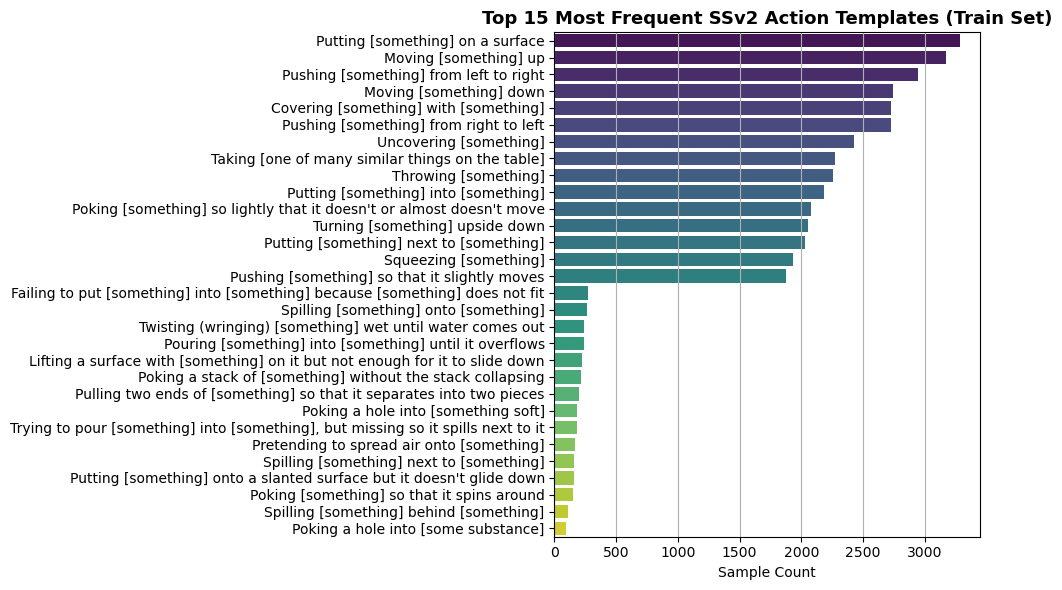

In [9]:
# top 15 and bottom 15 class counts (Train)
train_counts = df_train['template'].value_counts()

top15 = train_counts.head(15).reset_index()
bottom15 = train_counts.tail(15).reset_index()
top15 = pd.concat([top15, bottom15]).reset_index(drop=True)
top15.columns = ['template', 'count']

fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(zorder=0)
sns.barplot(data=top15, y='template', x='count', palette='viridis', ax=ax)

ax.set_title("Top 15 Most Frequent SSv2 Action Templates (Train Set)", fontsize=13, fontweight='bold')
ax.set_xlabel("Sample Count")
ax.set_ylabel('')  # Clear y-axis label text

plt.tight_layout()
plt.show()

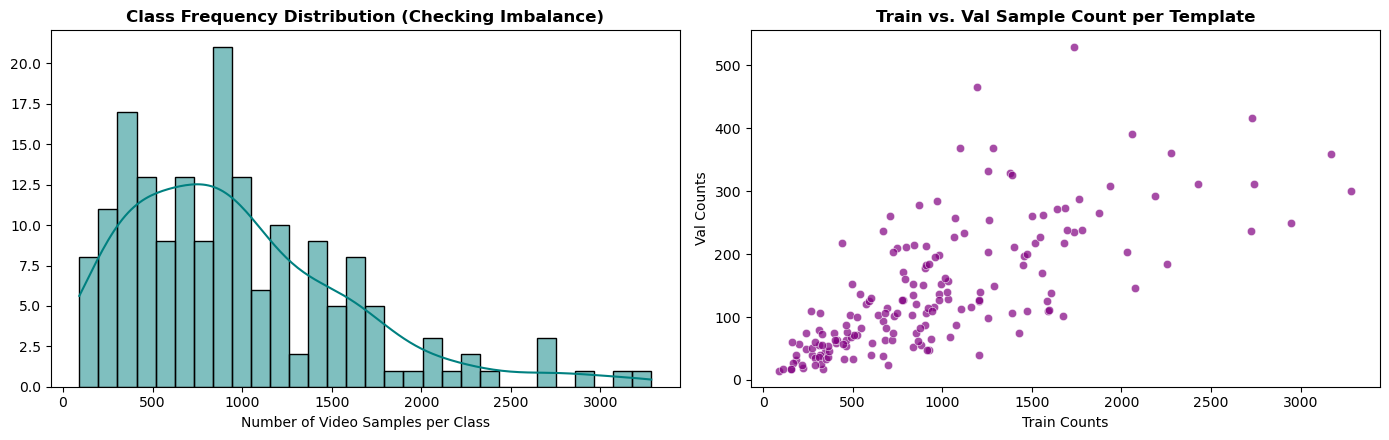

In [10]:
## Gemini AI code below: Long-Tail Distribution & Train/Val Split Consistency for ssv2 dataset
# Group class frequencies by split
class_counts = df.groupby(['template', 'split']).size().reset_index(name='count')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Class frequency distribution curve (Long-tail inspection)
sns.histplot(data=df_train['template'].value_counts(), kde=True, ax=axes[0], color='teal', bins=30)
axes[0].set_title("Class Frequency Distribution (Checking Imbalance)", fontweight='bold')
axes[0].set_xlabel("Number of Video Samples per Class")
axes[0].set_ylabel('')

# Plot 2: Compare train vs val sample counts across classes
sns.scatterplot(
    data=df.groupby('template')['split'].value_counts().unstack().fillna(0),
    x='train', y='val', alpha=0.7, color='purple', ax=axes[1]
)
axes[1].set_title("Train vs. Val Sample Count per Template", fontweight='bold')
axes[1].set_xlabel("Train Counts")
axes[1].set_ylabel("Val Counts")

plt.tight_layout()
plt.show()

In [16]:
pd.set_option('display.width', 10000)
print(df[0:2])

      id                                        label                                 template                    placeholders  split
0  78687  holding potato next to vicks vaporub bottle  Holding [something] next to [something]  [potato, vicks vaporub bottle]  train
1  42326               spreading margarine onto bread   Spreading [something] onto [something]              [margarine, bread]  train


In [24]:
# How many placeholders per example on average?
df.placeholders.apply(len).value_counts()

placeholders
1    111881
2     78565
3      3244
Name: count, dtype: int64

In [ ]:
# Some examples of 3-noun cases
df['len_placeholders'] = df.placeholders.apply(len)
df[df.len_placeholders==3].head(10)

,id,label,template,placeholders,split,len_placeholders
53,97012,failing to put led bulb box into glass bowl be...,Failing to put [something] into [something] be...,"[led bulb box, glass bowl, glass bowl]",train,3
268,75650,"putting sticky note, binder clip and pen on th...","Putting [something], [something] and [somethin...","[sticky note, binder clip, pen]",train,3
325,17814,putting 3 lemon onto plate,Putting [number of] [something] onto [something],"[3, lemon, plate]",train,3
352,85797,putting 3 pencil onto towel,Putting [number of] [something] onto [something],"[3, pencil, towel]",train,3
359,53084,putting 3 cloth clips onto the table,Putting [number of] [something] onto [something],"[3, cloth clips, the table]",train,3
549,162619,putting four plastic cards onto a lid,Putting [number of] [something] onto [something],"[four, plastic cards, a lid]",train,3
619,62023,"tipping plate with tumbler over, so tumbler fa...",Tipping [something] with [something in it] ove...,"[plate, tumbler, tumbler]",train,3
711,204218,"putting candy, lighter and battery on the table","Putting [something], [something] and [somethin...","[candy, lighter, battery]",train,3
933,129733,"putting a mirror, a hair tie and a comb on the...","Putting [something], [something] and [somethin...","[a mirror, a hair tie, a comb]",train,3
937,629,"pretending to pour water out of coffee mug, bu...",Pretending to pour [something] out of [somethi...,"[water, coffee mug, coffee mug]",train,3


In [ ]:
# For 3 noun cases which templates are seen?
df[df.len_placeholders==3].template.value_counts()

template
Putting [something], [something] and [something] on the table                      1109
Putting [number of] [something] onto [something]                                   1071
Tipping [something] with [something in it] over, so [something in it] falls out     381
Pretending to pour [something] out of [something], but [something] is empty         370
Failing to put [something] into [something] because [something] does not fit        313
Name: count, dtype: int64

In [33]:
import ast
import re

import nltk
from nltk.stem import WordNetLemmatizer

# Setup NLTK lemmatizer
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
lemmatizer = WordNetLemmatizer()

In [ ]:

# ==============================================================================
# STEP 1: noun EXTRACTION & NORMALIZATION (LEMMATIZATION & COMPOUND TEMPLATES)
# ==============================================================================

def extract_and_lemmatize_verb(template_str):
    """
    Extracts the primary verb from an SSv2 template, handling prefix compounds
    (e.g., 'Pretending to [verb]') and lemmatizing gerunds to base form.
    """
    # Remove bracketed placeholders
    clean = re.sub(r'\[.*?\]', '', template_str).strip()
    clean_lower = clean.lower()
    
    # Handle compound prefix templates before isolating the verb
    prefixes = ["pretending to", "failing to", "trying to", "showing that"]
    for prefix in prefixes:
        if clean_lower.startswith(prefix):
            clean_lower = clean_lower[len(prefix):].strip()
            break
            
    # Extract first word as verb
    words = clean_lower.split()
    if not words:
        return "unknown"
    first_word = words[0]
    
    # Lemmatize gerunds/verbs (e.g., 'holding' -> 'hold', 'spreading' -> 'spread')
    return lemmatizer.lemmatize(first_word, pos='v')



In [ ]:

# ==============================================================================
# STEP 2: MULTI-NOUN EXTRACTION & ROLE-AWARE PAIRING (NOUN 1 vs NOUN 2 vs NOUN 3)
# ==============================================================================

records = []

for idx, row in df.iterrows():
    verb = extract_and_lemmatize_verb(row['template'])
    placeholders = row['placeholders']
    
    # Safely parse stringified lists if loaded directly from CSV/JSON
    if isinstance(placeholders, str):
        try:
            placeholders = ast.literal_eval(placeholders)
        except (ValueError, SyntaxError):
            placeholders = []
            
    if isinstance(placeholders, list):
        for pos_idx, noun_phrase in enumerate(placeholders):
            noun_clean = str(noun_phrase).strip().lower()
            if noun_clean:
                # Assign role: noun_1 (Direct Object), noun_2 (Target/Location), noun_3 (Tertiary)
                role_label = f"noun_{pos_idx + 1}"
                records.append({
                    'video_id': row['id'],
                    'verb': verb,
                    'noun': noun_clean,
                    'role': role_label,
                    'split': row.get('split', 'train')
                })

# Long-format DataFrame containing every (Verb, Noun, Role) tuple
df_pairs = pd.DataFrame(records)

print(f"Extracted {len(df_pairs):,} total Verb-Noun-Role tuples.")
print(df_pairs.head())

Extracted 278,743 total Verb-Noun-Role tuples.
  video_id    verb                  noun    role  split
0    78687    hold                potato  noun_1  train
1    78687    hold  vicks vaporub bottle  noun_2  train
2    42326  spread             margarine  noun_1  train
3    42326  spread                 bread  noun_2  train
4   100904     put                   pen  noun_1  train


In [53]:
df_pairs.verb.nunique()

51

In [63]:

# ==============================================================================
# STEP 3: CO-OCCURRENCE METRICS (RAW COUNTS, CONDITIONAL PROBABILITY & PMI)
# ==============================================================================

def compute_cooccurrence_metrics(df_sub):
    """
    Computes:
    -> Raw Counts
    -> Conditional Probability P(Noun | Verb) (what nouns dominate a given action)
    -> PMI (Pointwise Mutual Information) to find unique/strong object-action bindings rather than just frequent generic items.
    """
    total_pairs = len(df_sub)
    
    # Group by (Verb, Noun)
    cooccur = df_sub.groupby(['verb', 'noun']).size().reset_index(name='raw_count')
    cooccur_rev = df_sub.groupby(['noun', 'verb']).size().reset_index(name='raw_count')
    
    # Verb and Noun marginal frequencies
    verb_counts = df_sub['verb'].value_counts().to_dict()
    noun_counts = df_sub['noun'].value_counts().to_dict()
    
    # Compute Conditional Probability: P(Noun | Verb)
    cooccur['p_noun_given_verb'] = cooccur.apply(
        lambda r: r['raw_count'] / verb_counts[r['verb']], axis=1
    )

    cooccur_rev['p_verb_given_noun'] = cooccur_rev.apply(
        lambda r: r['raw_count'] / noun_counts[r['noun']], axis=1
    )

    # Compute Pointwise Mutual Information (PMI)
    # PMI(v, n) = log2( P(v,n) / (P(v) * P(n)) )
    cooccur['pmi'] = cooccur.apply(
        lambda r: np.log2(
            (r['raw_count'] / total_pairs) / 
            ((verb_counts[r['verb']] / total_pairs) * (noun_counts[r['noun']] / total_pairs))
        ), axis=1
    )
    
    return cooccur, cooccur_rev

# Metrics specifically for Direct Objects (Noun 1)
df_noun1 = df_pairs[df_pairs['role'] == 'noun_1']
metrics_noun1, metrics_noun1_rev = compute_cooccurrence_metrics(df_noun1)

In [71]:

print("\n--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Noun|Verb) (what nouns dominate a given action) ---")
print(metrics_noun1.sort_values(by='p_noun_given_verb', ascending=False).head(20))


--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Noun|Verb) (what nouns dominate a given action) ---
          verb         noun  raw_count  p_noun_given_verb       pmi
26501     pour        water       1828           0.664486  5.570155
41975    spill        water        472           0.651034  5.540651
48792     tear        paper       2072           0.528706  4.337582
44922    stack            3        557           0.468461  6.351747
10046     fold        paper        339           0.269690  3.366416
57128   unfold        paper        237           0.224645  3.102759
38937     roll          pen        286           0.196159  3.479624
9375      fall        paper        497           0.156093  2.577521
44571  squeeze        paper        468           0.154711  2.564689
57318     wipe         dust        102           0.150888  7.904199
57457     wipe        water         99           0.146450  3.388322
23419     plug      charger        358           0.139408  5.2349

In [65]:
# Verify p(water|pour)
np.mean(df_pairs[(df_pairs.verb=='pour') & (df_pairs.role=='noun_1')].noun == 'water')

np.float64(0.6644856415848782)

In [66]:
print("\n--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Verb|Noun) (what verbs dominate a given noun) ---")
print(metrics_noun1_rev.sort_values(by='p_verb_given_noun', ascending=False).head(5))


--- Top Direct-Object (Noun 1) Pairs by Conditional Probability P(Verb|Noun) (what verbs dominate a given noun) ---
                                                    noun  verb  raw_count  p_verb_given_noun
57466                                   а ping pong ball  bury          1                1.0
0                                                    "h"   put          1                1.0
1                       "plugging a plug into a plugger"  move          1                1.0
2      "pretending to put a meter tape next to a stap...  plug          1                1.0
3      "putting a watch next to a glass bottle but no...   put          1                1.0


In [ ]:
# Lets see the second table that is verb given noun but with a raw_count threshold
print(metrics_noun1_rev[metrics_noun1_rev.raw_count>13].sort_values(by='p_verb_given_noun', ascending=False).head(20))

                    noun     verb  raw_count  p_verb_given_noun
38033   one of the forks     take         14           1.000000
12369       a tail light     poke         22           1.000000
5518        a head light     poke         14           1.000000
6301     a lighting pole     poke         14           1.000000
9974   a rearview mirror     poke         14           1.000000
33298               lady     show         85           0.988372
4780              a gate     open        165           0.959302
2251          a car door     open         40           0.952381
40347             person     show        135           0.950704
45193            rubbers     take         44           0.936170
18029               body    touch         63           0.926471
49155              stain  pretend         24           0.923077
9506              a plug     plug        106           0.898305
4881        a glass door     open         22           0.880000
39755                peg      put       

In [54]:
df_noun2 = df_pairs[df_pairs['role'] == 'noun_2']
metrics_noun2, _ = compute_cooccurrence_metrics(df_noun2)

print("\n--- Top inDirect-Object (Noun 2) Pairs by Conditional Probability P(Noun|Verb) (what indirect nouns dominate a given action) ---")
print(metrics_noun2.sort_values(by='p_noun_given_verb', ascending=False).head(10))



--- Top inDirect-Object (Noun 2) Pairs by Conditional Probability P(Noun|Verb) (what indirect nouns dominate a given action) ---
         verb     noun  raw_count  p_noun_given_verb       pmi
16334   scoop    spoon        455           0.337287  5.208988
2239    cover    paper        799           0.254135  4.248241
22902     try     wall        110           0.201097  4.774713
1230     bury  blanket        123           0.191589  5.650655
20769   throw      bed        243           0.179734  4.895538
2435      dig  blanket         80           0.165975  5.443608
20987   throw     wall        215           0.159024  4.436064
18262  spread    floor         74           0.154489  4.057587
2499      dig     sand         70           0.145228  6.152661
1300     bury     sand         91           0.141745  6.117633


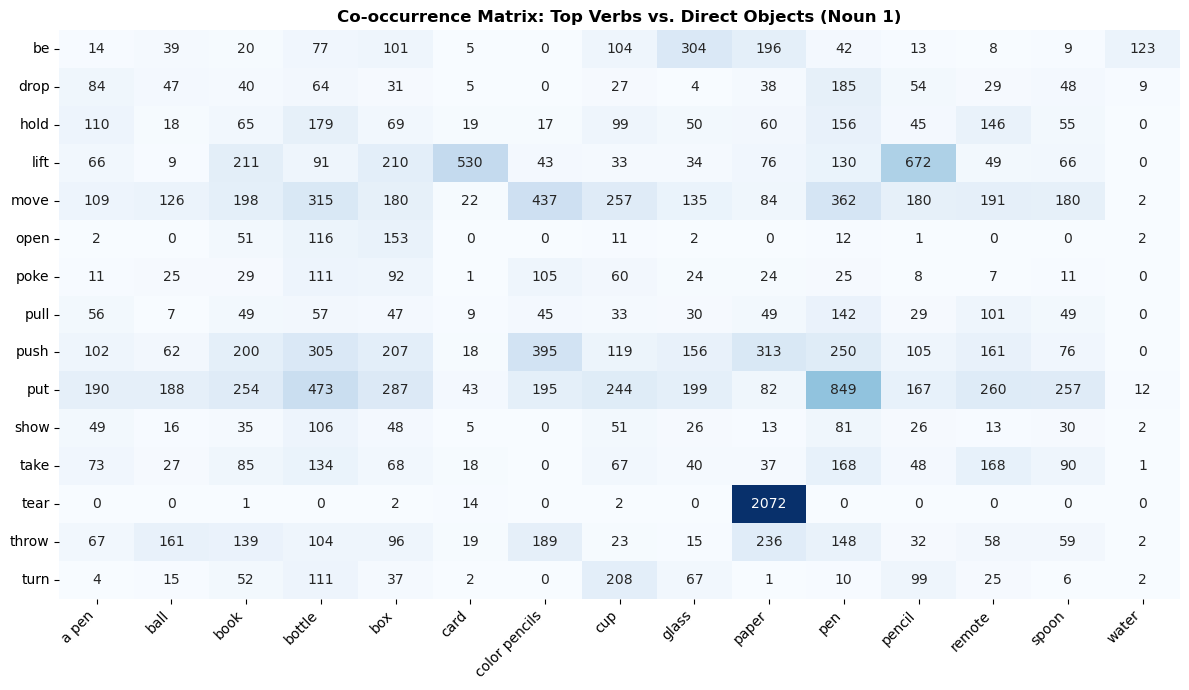

In [38]:

# ==============================================================================
# STEP 4: VISUALIZATIONS (HEATMAP & DISTRIBUTION)
# ==============================================================================

# Pivot table for top 15 Verbs and top 15 Nouns (Noun 1 Direct Objects)
top_verbs = df_noun1['verb'].value_counts().head(15).index
top_nouns = df_noun1['noun'].value_counts().head(15).index

df_top = df_noun1[(df_noun1['verb'].isin(top_verbs)) & (df_noun1['noun'].isin(top_nouns))]
pivot_counts = pd.crosstab(df_top['verb'], df_top['noun'])

# Plot 1: Co-occurrence Heatmap
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(pivot_counts, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)

ax.set_title("Co-occurrence Matrix: Top Verbs vs. Direct Objects (Noun 1)", fontweight='bold')
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_ylabel('')  # Clear y-axis label text

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# EK100

Notes:
- verb column and verb_class columns are different. verb_class is superset and the mapping can be found in EPIC_100_verb_classes.csv
- Same as above for noun classes

Analysis:
- Train / val set counts and percentage splits
- Top15/Bottom15 verbs
- Distribution of classes in the train/val sets

Noun analysis: 
- Lemmatizing verbs (we started with 171 unique templates and are now down to 51 verb classes)
- Examples have 1,2 or 3 nouns. I expanded the dataset to make a row for noun_1, noun_2 and noun_3. noun_1 is direct object of sentence usually so most analysis is restricted to it.
- Conditional probabilities P(Noun | Verb) (what nouns dominate a given action)
- Conditional Probabilities P(Verb | Noun) (what verbs dominate a given noun)
- Co-occurence matrix of top verbs and direct-object-nouns (Plot)

In [30]:
ek100_path = Path("/user/h.siddiqui/u27673/.project/dir.project/hamza/repos/vgd/epic_kitchens_100_annotations")
df_train = pd.read_csv(ek100_path / "EPIC_100_train.csv")
df_val = pd.read_csv(ek100_path / "EPIC_100_validation.csv")

# Add split column and concatenate
df_train['split'] = 'train'
df_val['split'] = 'val'
df = pd.concat([df_train, df_val], ignore_index=True)

df.head(2)

,narration_id,participant_id,video_id,narration_timestamp,start_timestamp,stop_timestamp,start_frame,stop_frame,narration,verb,verb_class,noun,noun_class,all_nouns,all_noun_classes,split
0,P01_01_0,P01,P01_01,00:00:01.089,00:00:00.14,00:00:03.37,8,202,open door,open,3,door,3,['door'],[3],train
1,P01_01_1,P01,P01_01,00:00:02.629,00:00:04.37,00:00:06.17,262,370,turn on light,turn-on,6,light,114,['light'],[114],train


In [39]:
# Load verb ID to verb name mapping
verbs_df = pd.read_csv(ek100_path / "EPIC_100_verb_classes.csv", header=0, usecols=[0, 1])
verb_map = dict(zip(verbs_df['id'], verbs_df['key']))

nouns_df = pd.read_csv(ek100_path / "EPIC_100_noun_classes.csv", header=0, usecols=[0, 1])
noun_map = dict(zip(nouns_df['id'], nouns_df['key']))

In [40]:
df['verb_class_name'] = df['verb_class'].map(verb_map)
df['noun_class_name'] = df['noun_class'].map(noun_map)
df.head(10)

,narration_id,participant_id,video_id,narration_timestamp,start_timestamp,stop_timestamp,start_frame,stop_frame,narration,verb,verb_class,noun,noun_class,all_nouns,all_noun_classes,split,verb_class_name,noun_class_name
0,P01_01_0,P01,P01_01,00:00:01.089,00:00:00.14,00:00:03.37,8,202,open door,open,3,door,3,['door'],[3],train,open,cupboard
1,P01_01_1,P01,P01_01,00:00:02.629,00:00:04.37,00:00:06.17,262,370,turn on light,turn-on,6,light,114,['light'],[114],train,turn-on,light
2,P01_01_10,P01,P01_01,00:00:23.340,00:00:24.97,00:00:26.20,1498,1572,open drawer,open,3,drawer,8,['drawer'],[8],train,open,drawer
3,P01_01_100,P01,P01_01,00:07:57.919,00:07:59.75,00:08:00.88,28785,28852,take cup,take,0,cup,13,['cup'],[13],train,take,cup
4,P01_01_101,P01,P01_01,00:08:00.020,00:08:01.47,00:08:02.21,28888,28932,open cupboard,open,3,cupboard,3,['cupboard'],[3],train,open,cupboard
5,P01_01_102,P01,P01_01,00:08:01.229,00:08:02.13,00:08:03.00,28927,28980,put cup into cupboard,put-into,5,cup,13,"['cup', 'cupboard']","[13, 3]",train,insert,cup
6,P01_01_103,P01,P01_01,00:08:03.919,00:08:05.22,00:08:07.21,29113,29232,take container and lid,take,0,container,21,"['container', 'lid']","[21, 6]",train,take,container
7,P01_01_104,P01,P01_01,00:08:07.610,00:08:08.38,00:08:09.12,29302,29347,put container on top of counter,put-on,1,container,21,"['container', 'top:counter']","[21, 42]",train,put,container
8,P01_01_105,P01,P01_01,00:08:09.860,00:08:12.00,00:08:12.74,29520,29564,open container,open,3,container,21,['container'],[21],train,open,container
9,P01_01_106,P01,P01_01,00:08:12.900,00:08:13.22,00:08:14.37,29593,29662,put container inside container,put-inside,5,container,21,"['container', 'container']","[21, 21]",train,insert,container


In [ ]:
# how many nouns per video? find length of all_nouns and then check value_counts.
df.all_nouns.apply(len).value_counts()

all_nouns
9     14339
7     11609
10     9889
8      8260
12     4443
11     3625
13     3454
14     3207
17     2479
16     2433
18     2225
15     2182
19     1490
21     1226
20      953
22      820
23      722
24      623
25      521
26      503
27      361
29      244
28      238
30      217
32      189
31      159
33      110
34       72
36       55
35       45
37       35
40       34
38       31
42       21
39       18
41        9
54        7
44        6
43        6
47        5
46        4
45        4
6         3
48        2
52        1
65        1
56        1
50        1
49        1
53        1
58        1
Name: count, dtype: int64

In [42]:
# 1. Train / Val Set Counts and Percentage Splits
split_summary = pd.DataFrame({
    'Count': df['split'].value_counts(),
    'Percentage (%)': (df['split'].value_counts(normalize=True) * 100).round(2)
})

print("=== Train / Validation Split Counts & Percentages ===")
print(split_summary)
print(f"\nTotal Samples: {len(df):,}")
print('-'*40)
print(f"Unique Verbs: {df.verb.nunique():,}")
print(f"Unique Verb Classes: {df.verb_class.nunique():,}")
print(f"Unique Nouns: {df.noun.nunique():,}")
print(f"Unique Noun Classes: {df.noun_class.nunique():,}")

=== Train / Validation Split Counts & Percentages ===
       Count  Percentage (%)
split                       
train  67217           87.43
val     9668           12.57

Total Samples: 76,885
----------------------------------------
Unique Verbs: 902
Unique Verb Classes: 97
Unique Nouns: 2,214
Unique Noun Classes: 293


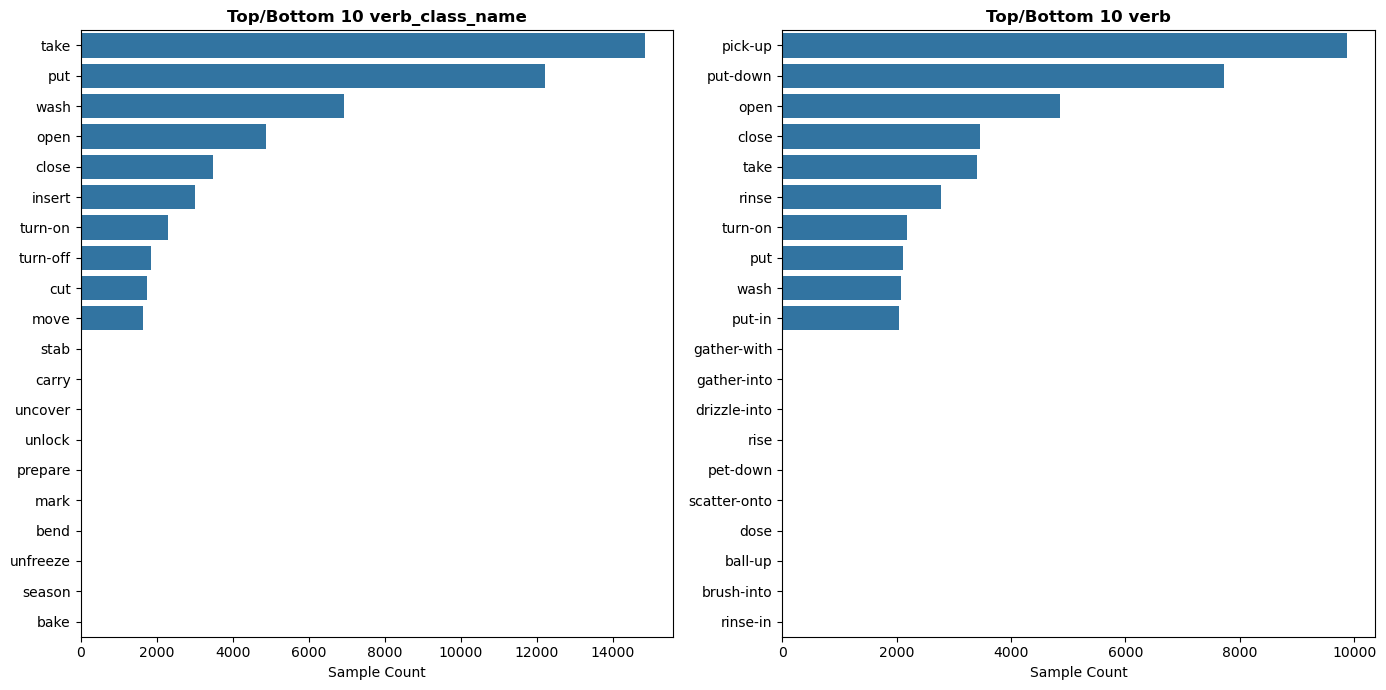

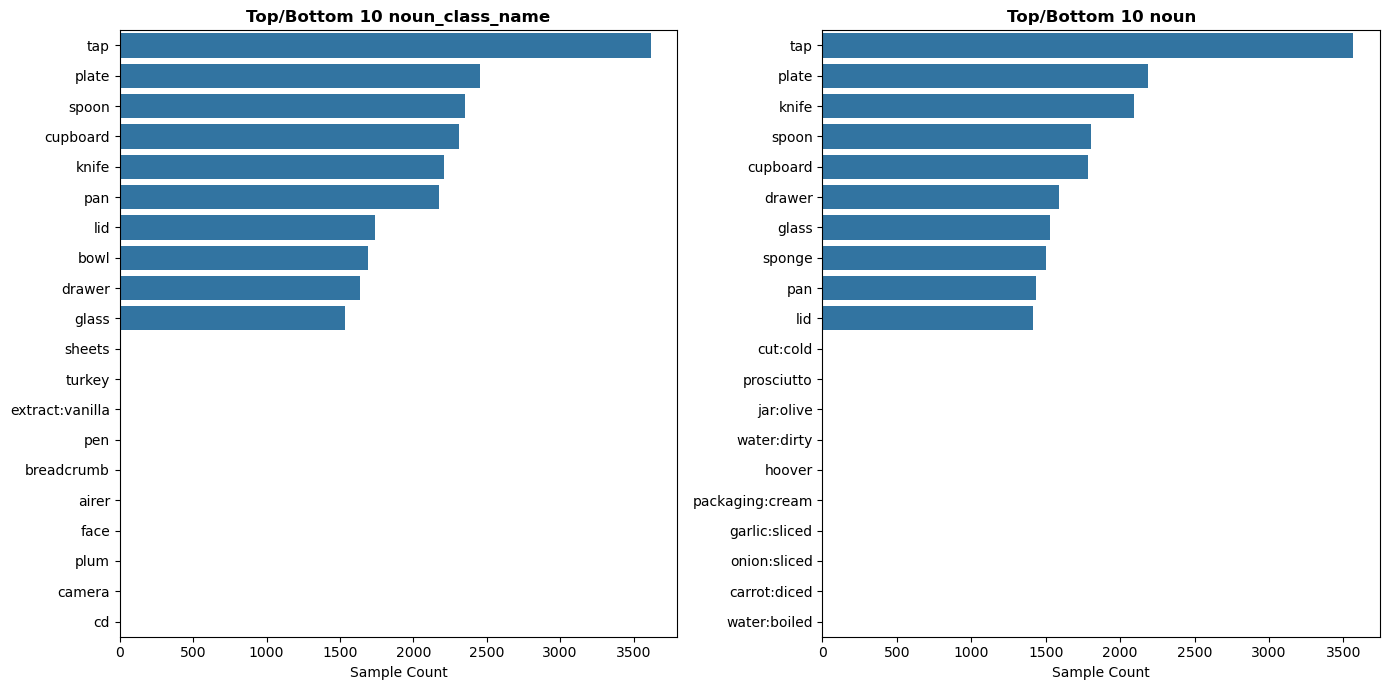

In [49]:
def plot_top_bottom(df_sub, col1, col2, how_many):
    counts = df_sub[col1].value_counts()    
    top_df = counts.head(how_many).reset_index(name='count')
    bot_df = counts.tail(how_many).reset_index(name='count')
    summary1 = pd.concat([top_df, bot_df], ignore_index=True)

    counts = df_sub[col2].value_counts()    
    top_df = counts.head(how_many).reset_index(name='count')
    bot_df = counts.tail(how_many).reset_index(name='count')
    summary2 = pd.concat([top_df, bot_df], ignore_index=True)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    # Plot 1
    sns.barplot(data=summary1, y=col1, x='count', ax=axes[0])
    axes[0].set_title(f"Top/Bottom {how_many} {col1}", fontweight='bold')
    axes[0].set_xlabel("Sample Count")
    axes[0].set_ylabel('')

    # Plot 2
    sns.barplot(data=summary2, y=col2, x='count', ax=axes[1])
    axes[1].set_title(f"Top/Bottom {how_many} {col2}", fontweight='bold')
    axes[1].set_xlabel("Sample Count")
    axes[1].set_ylabel('')

    plt.tight_layout()
    plt.show()



plot_top_bottom(df[df.split=='train'], 'verb_class_name', 'verb', 10)
plot_top_bottom(df[df.split=='train'], 'noun_class_name', 'noun', 10)


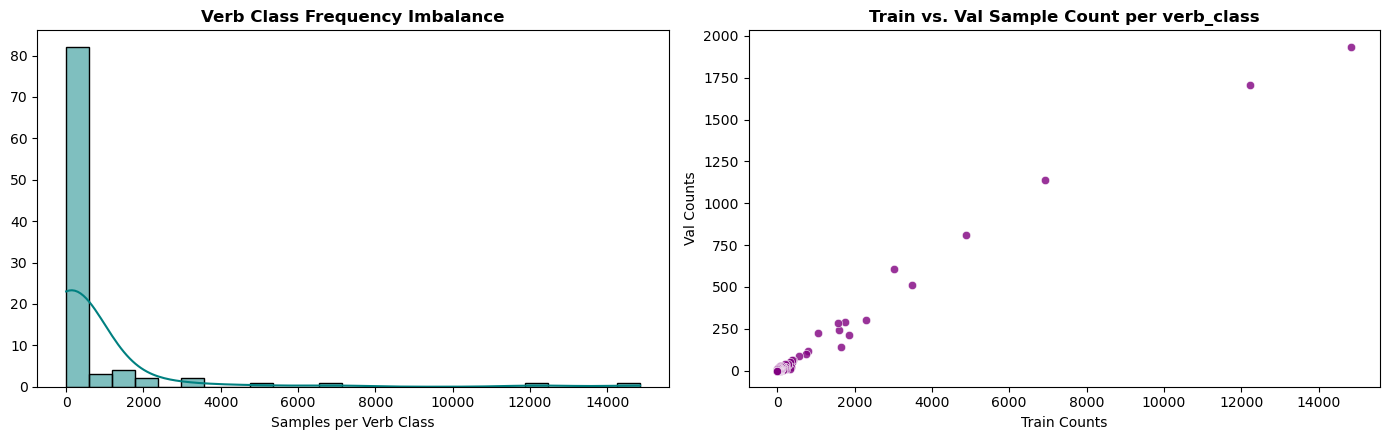

In [50]:
## By verb Class
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Class frequency distribution (Long-tail check)
train_counts = df[df['split'] == 'train']['verb_class'].value_counts()
sns.histplot(train_counts, kde=True, ax=axes[0], color='teal', bins=25)
axes[0].set_title("Verb Class Frequency Imbalance", fontweight='bold')
axes[0].set_xlabel("Samples per Verb Class")
axes[0].set_ylabel('')

# Plot 2: Compare train vs val sample counts per class
split_counts = df.groupby(['verb_class', 'split']).size().unstack(fill_value=0)
sns.scatterplot(data=split_counts, x='train', y='val', alpha=0.8, color='purple', ax=axes[1])
axes[1].set_title("Train vs. Val Sample Count per verb_class", fontweight='bold')
axes[1].set_xlabel("Train Counts")
axes[1].set_ylabel("Val Counts")

plt.tight_layout()
plt.show()

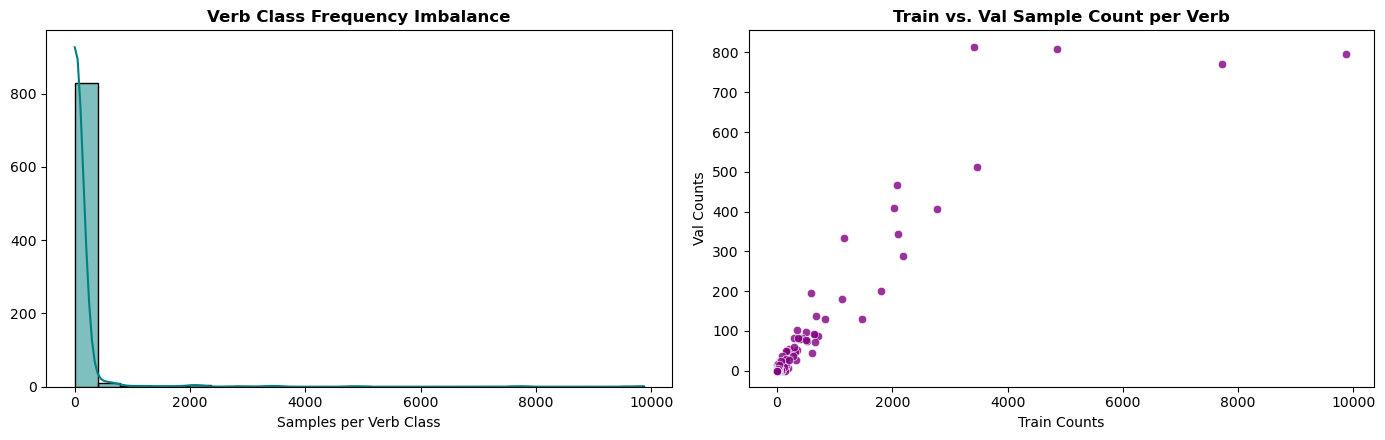

In [ ]:
## By verb 
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Class frequency distribution (Long-tail check)
train_counts = df[df['split'] == 'train']['verb'].value_counts()
sns.histplot(train_counts, kde=True, ax=axes[0], color='teal', bins=25)
axes[0].set_title("Verb Frequency Imbalance", fontweight='bold')
axes[0].set_xlabel("Samples per Verb Class")
axes[0].set_ylabel('')

# Plot 2: Compare train vs val sample counts per class
split_counts = df.groupby(['verb', 'split']).size().unstack(fill_value=0)
sns.scatterplot(data=split_counts, x='train', y='val', alpha=0.8, color='purple', ax=axes[1])
axes[1].set_title("Train vs. Val Sample Count per Verb", fontweight='bold')
axes[1].set_xlabel("Train Counts")
axes[1].set_ylabel("Val Counts")

plt.tight_layout()
plt.show()